# Simulating RobiReg Using Different Toehold Mediated Exchange (TMSE) mechanisms for a Simplified DNA Gate

**Installing and Initializing Modules**: See [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) documentation for additional details.

This notebook illustrate how to compile and simulate a simplified DNA gate implementing all TMSE mechanism: **`TwoStep()`**, and **`ThreeStep()`**, in TMSE-BioCRNpyler modules.

### Kinetic Model Deviations
* **Zero Reverse Rates**: All reverse (`rev`) rates are set to 0.
* **Minimized Unbinding Rate ($k_u \approx 0$)**: The release rate $k_u$ has been set to an extremely small value because it cannot be set to exactly zero.

### Specific Features
* Specifying strand exchange molecules directly from a dictionary using `TMSE()`.
* Generating strand exchange reactions at different levels of abstraction:
  * For **TwoStepTMSE()**, Complex 1 is translated.
  * For **ThreeStepTMSE()**, Complex 2 is translated into an arbitrary protein named **Protein X**.

## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path
from matplotlib.gridspec import GridSpec
from biocrnpyler import ComplexSpecies

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

In [2]:
# Simulate all models - example for 4 hours
timepoints = np.linspace(0,4,5001)*3600

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

In [3]:
def plot_subplots(tmse_steps, time, dict_specs, ax, ax_num, plot_dict):
    """Plots 'complex' species on the top row and 'protein' species on the bottom row.

    ax: tuple, list, or array of [ax_top, ax_bottom] for the current column.
    """
    ax_top, ax_bottom = ax[0], ax[1]


    # --- Top Row: Complexes ---
    for col in R.columns:
        if "complex" in col:
            data = R[col]
            ax_top.plot(
                time,
                data / 1000,
                label=plot_dict[col][1],
                linewidth=2,
                color=plot_dict[col][0],
                linestyle=plot_dict[col][2],
            )

    for key in dict_specs.keys():
        data = R[key]
        ax_top.plot(
            time,
            data / 1000,
            label=dict_specs[key][1],
            color=dict_specs[key][0],
            linewidth=2,
            linestyle=dict_specs[key][2],
        )

    # --- Bottom Row: Protein X ---
        target_col = next(
            (c for c in ["protein_x", "protein_X"] if c in R.columns), None
        )

        if target_col is not None:
            style = plot_dict.get(
                target_col, ("tab:blue", target_col.replace("_", " ").title(), "-")
            )
            ax_bottom.plot(
                time,
                R[target_col] / 1000,
                label=style[1],
                linewidth=2,
                color=style[0],
                linestyle=style[2],
            )

    # Annotate column/step on top plot
    ax_top.text(
        0.70,
        0.75,
        tmse_steps,
        fontsize=22,
        fontstyle="italic",
        fontweight="light",
        fontfamily="sans-serif",
        transform=ax_top.transAxes,
    )

    # Set ranges
    ax_top.set_xlim(0, 4)
    ax_bottom.set_xlim(0, 4)
    ax_top.set_ylim(-0.01, 0.16)
    ax_bottom.set_ylim(-0.01, 75)

    # Set tick font sizes for both rows
    for a in (ax_top, ax_bottom):
        for tick in a.get_xticklabels():
            tick.set_fontsize(22)
        for tick in a.get_yticklabels():
            tick.set_fontsize(22)

    # Share/hide tick labels between rows to avoid clutter
    # plt.setp(ax_top.get_xticklabels(), visible=False)
    ax_top.set_xlabel("Time (h)", fontsize=22)
    ax_bottom.set_xlabel("Time (h)", fontsize=22)

    # Y-axis labels and visibility per column
    if ax_num == 0:
        ax_top.set_ylabel("Concentrations (μmol/L)", color="black", fontsize=22)
        ax_bottom.set_ylabel(
            "Concentrations (μmol/L)", color="black", fontsize=22
        )
    else:
        plt.setp(ax_top.get_yticklabels(), visible=False)
        plt.setp(ax_bottom.get_yticklabels(), visible=False)

## Simplified DNA AND Gate simulation

![Simplified DNA AND Gate](../schematics/Figure_RiboReg.png)
(A) Substrates (left) and products (right) involved in the TMSE mechanism. (B) Schematic representation of different TMSE mechanisms available: (i) `TwoStepTMSE()`, and (ii) `ThreeStepTMSE()`.

In [4]:
# Define initial DNA and Reporter RNA
sim_inputs = {
    'DNA_1': ['Input',2], # Input DNA
    'DNA_5':['Gate',2,4], # Gate DNA
    'RNA_1':['Reporter',4]} # Reporter DNA
     
# Components
step_tmse = TMSE(sim_inputs)

# Parameters and initical conditions
parameters_AND = {"kx":5e4/1e9,
                  "krev":0,
                  "krep":5e4/1e9,
                  "kb":5e4/1e9,
                  "kb_rev":0,
                  "ku":0.00000001,
                  "ku_rev":0,
                  } 

initial_concentration_dict = {'dna_Input_2':100,
                              'dna_Gate_2_4':200,
                              'dna_Reporter_4':150}

# Dictionary of TMSE mechanism
tmse_conditions = {'Two-Step': [TwoStepTMSE()],
                   'Three-Step': [ThreeStepTMSE()]
                   }

# Dictionary for plotting
list_species=  {'dna_Signal_4':['rebeccapurple', 'DNA signal 4', 'dashed'],}
plot_dict= {'complex_dna_Gate_2_4_dna_Input_2_':['navy', 'Complex 1', 'solid'],
            'complex_dna_GateOut_2_2_dna_Output_2_4_': ['grey', 'Complex 2', 'solid']}

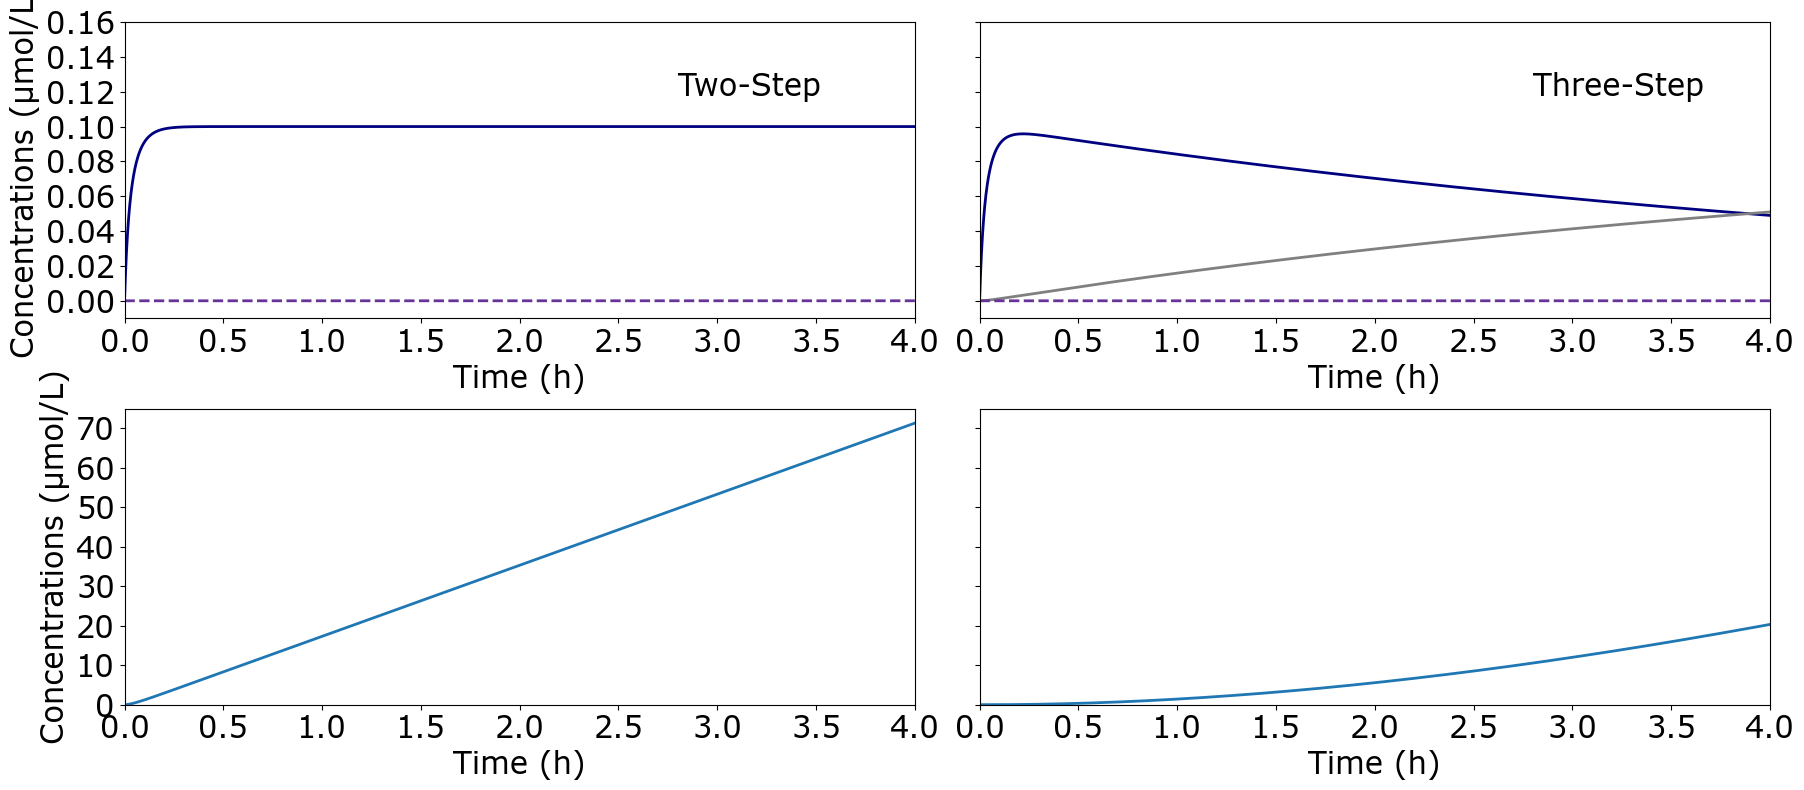

In [5]:
fig = plt.figure(figsize=(35, 8))
gs = GridSpec(2, 4, figure=fig, width_ratios=[2, 2, 2, 2], height_ratios=[1, 1])

# Using enumerate handles arbitrary numbers of conditions (up to 4)
for ax_num, key in enumerate(tmse_conditions.keys()):
    mech_tmse = tmse_conditions[key][0]
    tmse_mechanisms = {mech_tmse.mechanism_type: mech_tmse}

    # Make Mixture and Compile
    M_DNAseesaw_AND = Mixture(
        "SeeSaw_AND",
        components=[step_tmse],
        parameters=parameters_AND,
        mechanisms=tmse_mechanisms,
    )

    # Compile the CRN with Mixture.compile_crn
    CRN_DNAseesaw_AND = M_DNAseesaw_AND.compile_crn()

    # Adding TL
    last_complex = next(
        ( s for s in reversed(CRN_DNAseesaw_AND.species)
            if isinstance(s, ComplexSpecies)
        ),
        None,
    )

    mech_tl = SimpleTranslation()
    tl_mechanism = {mech_tl.mechanism_type: mech_tl}

    rna_assembly = RNAassembly(
        last_complex, transcript=last_complex, rbs="Strong", protein="X"
    )
    M_Tl = Mixture(
        "Tl",
        components=[rna_assembly],
        parameters=parameters_AND,
        mechanisms=tl_mechanism,
    )
    Tl_crn = M_Tl.compile_crn()

    CRN_DNAseesaw_AND.add_reactions(Tl_crn.reactions)

    # Simulate
    try:
        R = CRN_DNAseesaw_AND.simulate_with_bioscrape_via_sbml(
            timepoints=timepoints,
            initial_condition_dict=initial_concentration_dict,
        )
        time = R["time"] / 3600

        # Create top (row 0) and bottom (row 1) axes for current column
        ax_top = fig.add_subplot(gs[0, ax_num])
        ax_bottom = fig.add_subplot(gs[1, ax_num], sharex=ax_top)

        # Plot across both rows
        plot_subplots(
            key, time, list_species, (ax_top, ax_bottom), ax_num, plot_dict
        )

    except ModuleNotFoundError:
        print("Plotting Modules not installed.")

# Call tight_layout BEFORE savefig so bounding boxes render correctly
plt.tight_layout()
plt.savefig(f"{figs_dir}/SI_riboreg.svg")
plt.show()

In [6]:
# Print CRN reactions (Optional)
print(CRN_DNAseesaw_AND.pretty_print(show_rates = True, how_attributes = True, 
                            show_materials = True, show_keys = False))

Species(N = 10) = {
    complex[dna[Gate_2_4]:dna[Input_2]] (@ 0),  
    complex[dna[GateOut_2_2]:dna[Output_2_4]] (@ 0),  
    protein[X] (@ 0),  
    dna[Signal_4] (@ 0),  
    dna[Reporter_4] (@ 0),  
    dna[ReporterOut_4] (@ 0),  
    dna[Output_2_4] (@ 0),  
    dna[Input_2] (@ 0),  
    dna[Gate_2_4] (@ 0),  
    dna[GateOut_2_2] (@ 0),  
}

Reactions (5) = [
0. dna[Gate_2_4]+dna[Input_2] --> complex[dna[Gate_2_4]:dna[Input_2]]
 Kf=k_forward * dna_Gate_2_4 * dna_Input_2
  k_forward=5e-05

1. complex[dna[Gate_2_4]:dna[Input_2]] --> complex[dna[GateOut_2_2]:dna[Output_2_4]]
 Kf=k_forward * complex_dna_Gate_2_4_dna_Input_2_
  k_forward=5e-05

2. complex[dna[Gate_2_4]:dna[Input_2]] --> dna[Output_2_4]+dna[GateOut_2_2]
 Kf=k_forward * complex_dna_Gate_2_4_dna_Input_2_
  k_forward=1e-08

3. dna[Output_2_4]+dna[Reporter_4] --> dna[Signal_4]+dna[ReporterOut_4]
 Kf=k_forward * dna_Output_2_4 * dna_Reporter_4
  k_forward=5e-05

4. complex[dna[GateOut_2_2]:dna[Output_2_4]] --> complex[dna[

# Computing environment

In [7]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.4.0
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.3

